# Phase 1: Exploratory Data Analysis

**Project:** Server Resource Utilization Forecasting Using Time Series Analysis and Machine Learning  
**Selected series:** `ec2_cpu_utilization_5f5533.csv` from NAB's `realAWSCloudwatch` collection.

This notebook performs only Phase 1 exploration. NAB is an anomaly-benchmark repository, but this project uses only the timestamp and CPU-utilization values for later forecasting work. NAB anomaly labels are deliberately not loaded or used here.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style='whitegrid')

# This lets the notebook run from either the project root or notebooks/.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / 'data/external/NAB/data/realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv'
FIGURE_DIR = PROJECT_ROOT / 'reports/figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print(f'Data file: {DATA_PATH}')

Data file: /Users/sanchitkhandelwal/Desktop/server-resource-forecasting/data/external/NAB/data/realAWSCloudwatch/ec2_cpu_utilization_5f5533.csv


## Load the data

The CSV has a timestamp column and a CPU-utilization value column. Parsing timestamps at load time makes time-based checks explicit.

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=['timestamp'])
df.head(10)

,timestamp,value
0,2014-02-14 14:27:00,51.846
1,2014-02-14 14:32:00,44.508
2,2014-02-14 14:37:00,41.244
3,2014-02-14 14:42:00,48.568
4,2014-02-14 14:47:00,46.714
5,2014-02-14 14:52:00,44.986
6,2014-02-14 14:57:00,49.108
7,2014-02-14 15:02:00,40.470
8,2014-02-14 15:07:00,53.404
9,2014-02-14 15:12:00,45.400


## Structure and data types

In [3]:
print(f'Dataset shape (rows, columns): {df.shape}')
print('\nData types:')
print(df.dtypes)

Dataset shape (rows, columns): (4032, 2)

Data types:
timestamp    datetime64[us]
value               float64
dtype: object


## Data-quality checks

Missing observations and repeated timestamps must be known before any future chronological split or model is considered.

,missing_values
timestamp,0
value,0


Duplicate timestamps: 0


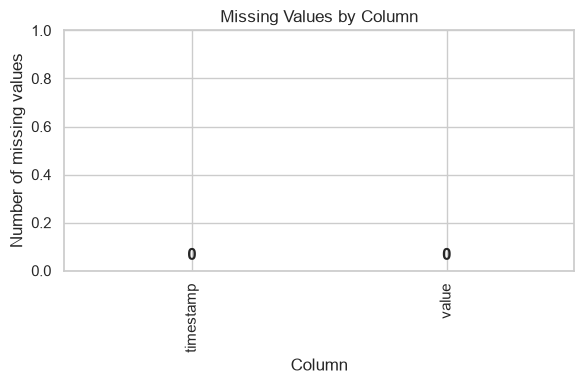

In [4]:
missing_summary = df.isna().sum().rename('missing_values').to_frame()
duplicate_timestamps = df['timestamp'].duplicated().sum()

display(missing_summary)
print(f'Duplicate timestamps: {duplicate_timestamps}')

ax = missing_summary.plot(kind='bar', legend=False, color='#4C78A8', figsize=(6, 4))
ax.set_title('Missing Values by Column')
ax.set_xlabel('Column')
ax.set_ylabel('Number of missing values')
# A 0-to-1 axis and labels make verified zero counts visible.
ax.set_ylim(0, 1)
for index, count in enumerate(missing_summary['missing_values']):
    ax.text(index, 0.03, str(count), ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '01_ec2_cpu_5f5533_missing_data_summary.png', dpi=150)
plt.show()

**Observation:** The printed checks above report the actual missing-value and duplicate-timestamp counts. These checks are descriptive only; no values are filled or removed in Phase 1.

## Descriptive statistics

In [5]:
df[['value']].describe()

,value
count,4032.000000
mean,43.110372
std,4.303565
min,34.766000
25%,39.296000
50%,42.918000
75%,46.006000
max,68.092000


## Timestamp range and sampling interval

A regular interval is useful for forecasting because it gives each observation the same time meaning. The mode is used as the most common interval, and its share of all consecutive intervals is shown below.

In [6]:
ordered_timestamps = df['timestamp'].sort_values()
intervals = ordered_timestamps.diff().dropna()
sampling_interval = intervals.mode().iloc[0]
regularity_percent = (intervals == sampling_interval).mean() * 100

print(f'Timestamp range: {ordered_timestamps.min()} to {ordered_timestamps.max()}')
print(f'Elapsed range: {ordered_timestamps.max() - ordered_timestamps.min()}')
print(f'Most common sampling interval: {sampling_interval}')
print(f'Intervals matching the most common interval: {regularity_percent:.2f}%')
print(f'Number of observations: {len(df)}')

Timestamp range: 2014-02-14 14:27:00 to 2014-02-28 14:22:00
Elapsed range: 13 days 23:55:00
Most common sampling interval: 0 days 00:05:00
Intervals matching the most common interval: 100.00%
Number of observations: 4032


**Observation:** Use the displayed interval distribution as evidence for regularity. This notebook does not impute timestamps or assume a seasonal cycle from a short visual inspection.

## Visual exploration

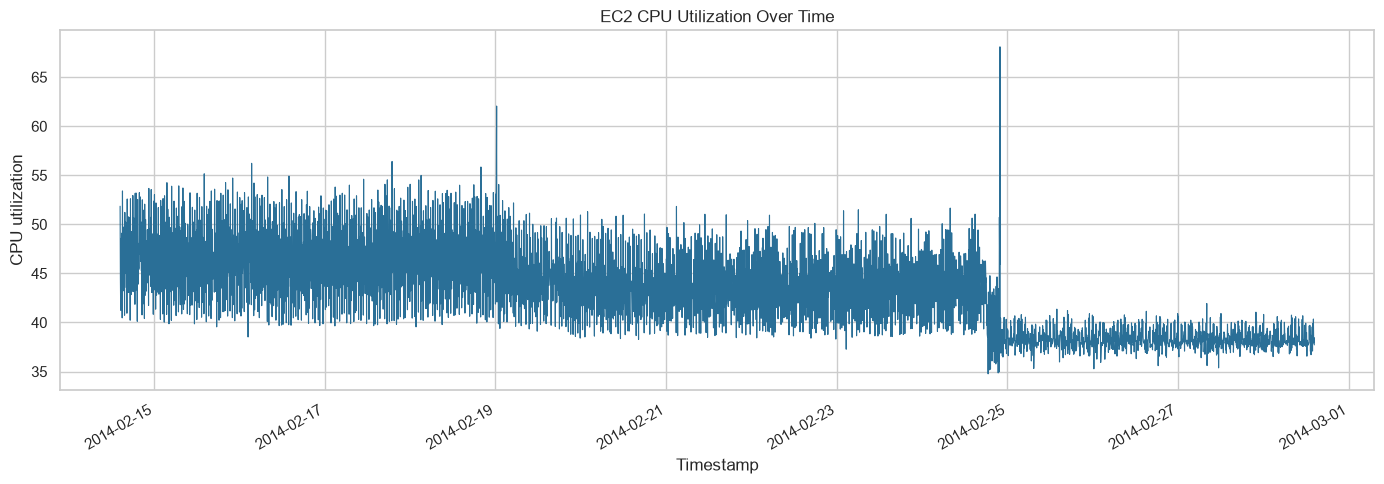

In [7]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df['timestamp'], df['value'], linewidth=0.8, color='#2A6F97')
ax.set_title('EC2 CPU Utilization Over Time')
ax.set_xlabel('Timestamp')
ax.set_ylabel('CPU utilization')
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig(FIGURE_DIR / '01_ec2_cpu_5f5533_time_series.png', dpi=150)
plt.show()

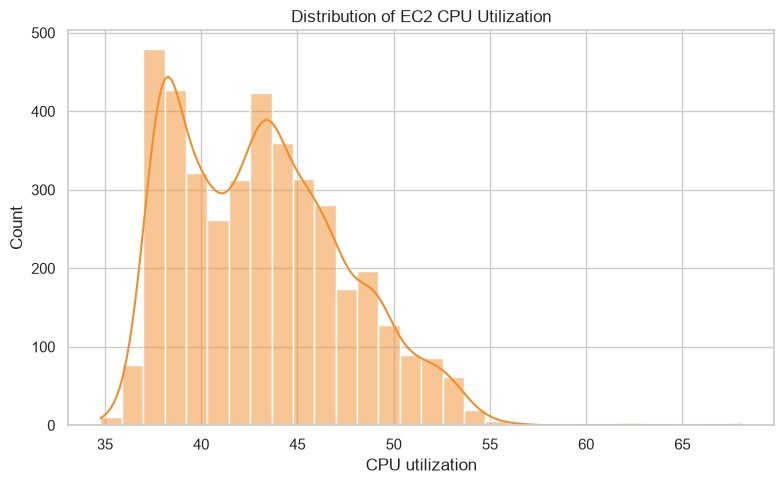

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df['value'], bins=30, kde=True, color='#F28E2B', ax=ax)
ax.set_title('Distribution of EC2 CPU Utilization')
ax.set_xlabel('CPU utilization')
ax.set_ylabel('Count')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '01_ec2_cpu_5f5533_histogram.png', dpi=150)
plt.show()

## Phase 1 interpretation

The time plot shows observed variation around a higher level early in the period, followed by a visibly lower level after about 25 February, plus occasional spikes. This is descriptive evidence of a possible level change; it is not a stationarity or seasonality result. Any repeated shape remains a Phase 2 hypothesis to test. Forecasting models are intentionally outside the scope of this notebook.